IMPORTS

In [50]:
import math
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchdiffeq import odeint, odeint_adjoint
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

$$
\begin{cases}
\dot{x} = -x^3 + ax + by\\
\dot{y} = -y^3 + cx + dy
\end{cases}
$$

In [51]:
class SwitchingNeurons(nn.Module):
  def __init__(self, a = 1.0, b=0.2, c=0.2, d=1.0):
        super().__init__()

        self.a=a
        self.b=b
        self.c=c
        self.d=d
    

  def forward(self,t,z):
        x, y = z[...,0], z[...,1]
        dx = -x**3 + self.a*x + self.b*y
        dy = -y**3 + self.c*x + self.d*y

        return torch.stack([dx,dy], dim= -1)

Make DataSet

In [52]:
#dataset

def makeDataSet(n_traj=200, T=3.0, step=60, noise_std=0.02):
    gt=SwitchingNeurons().to(device)
    t=torch.linspace(0.0, T, step, device=device)

    x0 = 1.2*(2*torch.rand(n_traj)-1)
    y0 = 1.2*(2*torch.rand(n_traj)-1)
    z0=torch.stack([x0,y0], dim=-1)

    with torch.no_grad():
        z_traj= odeint(gt, z0, t, method = "dopri5")
        z_traj=z_traj.transpose(0,1).contiguous()
        if noise_std > 0:
             z_traj = z_traj + noise_std * torch.randn_like(z_traj)
    return z0, t, z_traj

In [53]:
z0_all, t_eval, Z_all = makeDataSet(n_traj=400, T=1.0, step=100, noise_std=0.01)
N=z0_all.size(0)
perm=torch.randperm(N)


train_idx=perm[: int(0.8*N)] #перемешанные индексы 
test_idx=perm[int(0.8*N):]

z0_train, z0_test = z0_all[train_idx], z0_all[test_idx]
Z_train, Z_test = Z_all[train_idx], Z_all[test_idx]

train_load = DataLoader(TensorDataset(z0_train, Z_train), batch_size=64, shuffle=True)
test_load = DataLoader(TensorDataset(z0_test, Z_test), batch_size=128, shuffle=False)



/home/ekaterina2002/ODES/.venv/lib/python3.10/site-packages/torchdiffeq/_impl/misc.py:306: UserWarning: t is not on the same device as y0. Coercing to y0.device.
  warnings.warn("t is not on the same device as y0. Coercing to y0.device.")


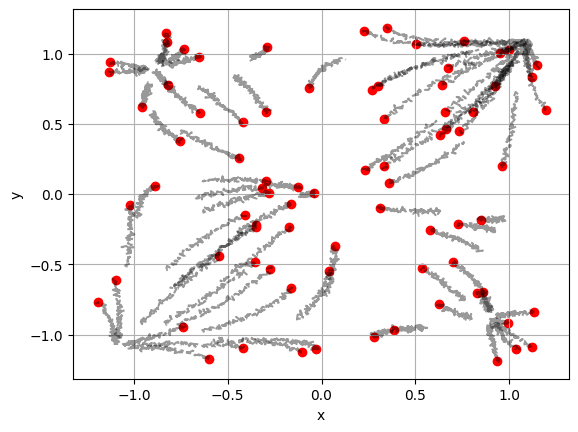

In [55]:


for z0_batch, Z_batch in test_load:
    for i in range (Z_batch.size(0)):
        x = Z_batch[i,:,0].cpu().numpy()
        y = Z_batch[i,:,1].cpu().numpy()
        plt.plot(x,y,'k--',alpha=0.4)

   
    plt.scatter(z0_batch[:, 0].cpu().numpy(),
                z0_batch[:, 1].cpu().numpy(),
                color='red')
    break

plt.xlabel("x")
plt.ylabel("y")
plt.grid()
plt.show()
        

In [56]:
class ODEmodel(nn.Module):
    def __init__(self,state_dim=2, hidden=64, time_dependent=True):
        super().__init__()
        self.time_dependent = time_dependent

        in_dim = state_dim+(1 if time_dependent else 0)
        self.net=nn.Sequential(
            nn.Linear(in_dim, hidden),nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden,state_dim),
        )

        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)
        

    def forward(self, t,z):
        if z.dim()==1:
            z = z.unsqueeze(0)
        if self.time_dependent:
            t_col = torch.full((z.size(0), 1), float(t), device=z.device, dtype=z.dtype)
            h = torch.cat([z, t_col], dim=-1)
        else:
            h = z
        return self.net(h)
    
class NeuralODE(nn.Module):
     def __init__(self, func, use_adjoint, rtol=1e-3, atol=1e-4, method="dopri5"):
            super().__init__()
            self.func = func
            self.use_adjoint = use_adjoint
            self.rtol = rtol
            self.atol = atol
            self.method = method


     def forward(self,z0,t):
            solver= odeint_adjoint if self.use_adjoint else odeint
            Z = solver(self.func, z0, t , rtol=self.rtol, atol=self.atol, method=self.method)
            return Z.transpose(0, 1).contiguous()



In [57]:
def mse ( z_hat, z_true):
    return torch.mean((z_hat-z_true)**2)

In [58]:
def evaluate(model, loader, t_eval):
    model.eval()
    mse_sum, count = 0.0, 0
    with torch.no_grad():
        for z0, Z in loader:
            z0, Z = z0.to(device), Z.to(device)
            Z_pred=model(z0,t_eval)
            mse_sum += mse(Z_pred, Z).item()*z0.size(0)
            count +=z0.size(0)
        return mse_sum/count

In [59]:
func_reg = ODEmodel().to(device)
node_reg = NeuralODE(func_reg, use_adjoint=False).to(device)


print("Training Neural ODE (regular)...")
node_reg = train(node_reg, train_load, t_eval, tag="REG")


func_adj = ODEmodel().to(device)
node_adj = NeuralODE(func_adj, use_adjoint=True).to(device)

print("\nTraining Neural ODE (adjoint)...")
node_adj = train(node_adj, train_load, t_eval, tag="ADJ")

print("\n=== Final MSE ===")
print("Regular :", evaluate(node_reg, train_load, t_eval), evaluate(node_reg, test_load,  t_eval))
print("Adjoint :", evaluate(node_adj, train_load, t_eval), evaluate(node_adj, test_load,  t_eval))

Training Neural ODE (regular)...
[REG] Epoch 012 | train 0.009538 | test 0.009677
[REG] Epoch 024 | train 0.002063 | test 0.002219
[REG] Epoch 036 | train 0.001401 | test 0.001609
[REG] Epoch 048 | train 0.001057 | test 0.001185
[REG] Epoch 060 | train 0.001029 | test 0.001247

Training Neural ODE (adjoint)...
[ADJ] Epoch 012 | train 0.011591 | test 0.011679
[ADJ] Epoch 024 | train 0.001553 | test 0.001778
[ADJ] Epoch 036 | train 0.001165 | test 0.001292
[ADJ] Epoch 048 | train 0.000964 | test 0.001059
[ADJ] Epoch 060 | train 0.000783 | test 0.000921

=== Final MSE ===
Regular : 0.0010285973898135127 0.001247061532922089
Adjoint : 0.0007825632696039974 0.0009213140001520514


In [60]:
def compare(model, z0_all, Z_all, t_eval, n, k):
    model.eval()
    with torch.no_grad():
        z0_all = z0_all.to(device)
        Z_all = Z_all.to(device)
        Z_pred = model(z0_all, t_eval) 

    for i in range(n):
        print(f"\nTrajectory {i}")
        print("\nDataSet trajectory:")
        print(Z_all[i, :k].cpu().numpy())

        print("\nPredicted trajectory:")
        print(Z_pred[i, :k].cpu().numpy())


In [49]:
compare(node_adj, z0_all, Z_all, t_eval, 4, 5)


Trajectory 0

DataSet trajectory:
[[-1.1935027  -0.88151646]
 [-1.1886902  -0.89849013]
 [-1.1871248  -0.90796983]
 [-1.1942385  -0.9091696 ]
 [-1.199714   -0.90216583]]

Predicted trajectory:
[[-1.1973587  -0.89023924]
 [-1.1967787  -0.89361656]
 [-1.196214   -0.8969629 ]
 [-1.1956648  -0.90027833]
 [-1.1951311  -0.9035632 ]]

Trajectory 1

DataSet trajectory:
[[ 0.43218902 -0.48114473]
 [ 0.4363659  -0.4809595 ]
 [ 0.433622   -0.49164325]
 [ 0.43592268 -0.4866304 ]
 [ 0.4539733  -0.48753655]]

Predicted trajectory:
[[ 0.43591464 -0.4839595 ]
 [ 0.43855044 -0.48708075]
 [ 0.44118035 -0.49018997]
 [ 0.4438042  -0.49328694]
 [ 0.44642186 -0.49637148]]

Trajectory 2

DataSet trajectory:
[[-0.5703042   0.39661556]
 [-0.5760692   0.41529837]
 [-0.5692434   0.4375485 ]
 [-0.57531077  0.40555874]
 [-0.5889572   0.39753026]]

Predicted trajectory:
[[-0.57446325  0.40506694]
 [-0.5772827   0.40771315]
 [-0.58008623  0.4103563 ]
 [-0.5828738   0.41299614]
 [-0.5856453   0.41563228]]

Trajector